Drawing Cluster 1...


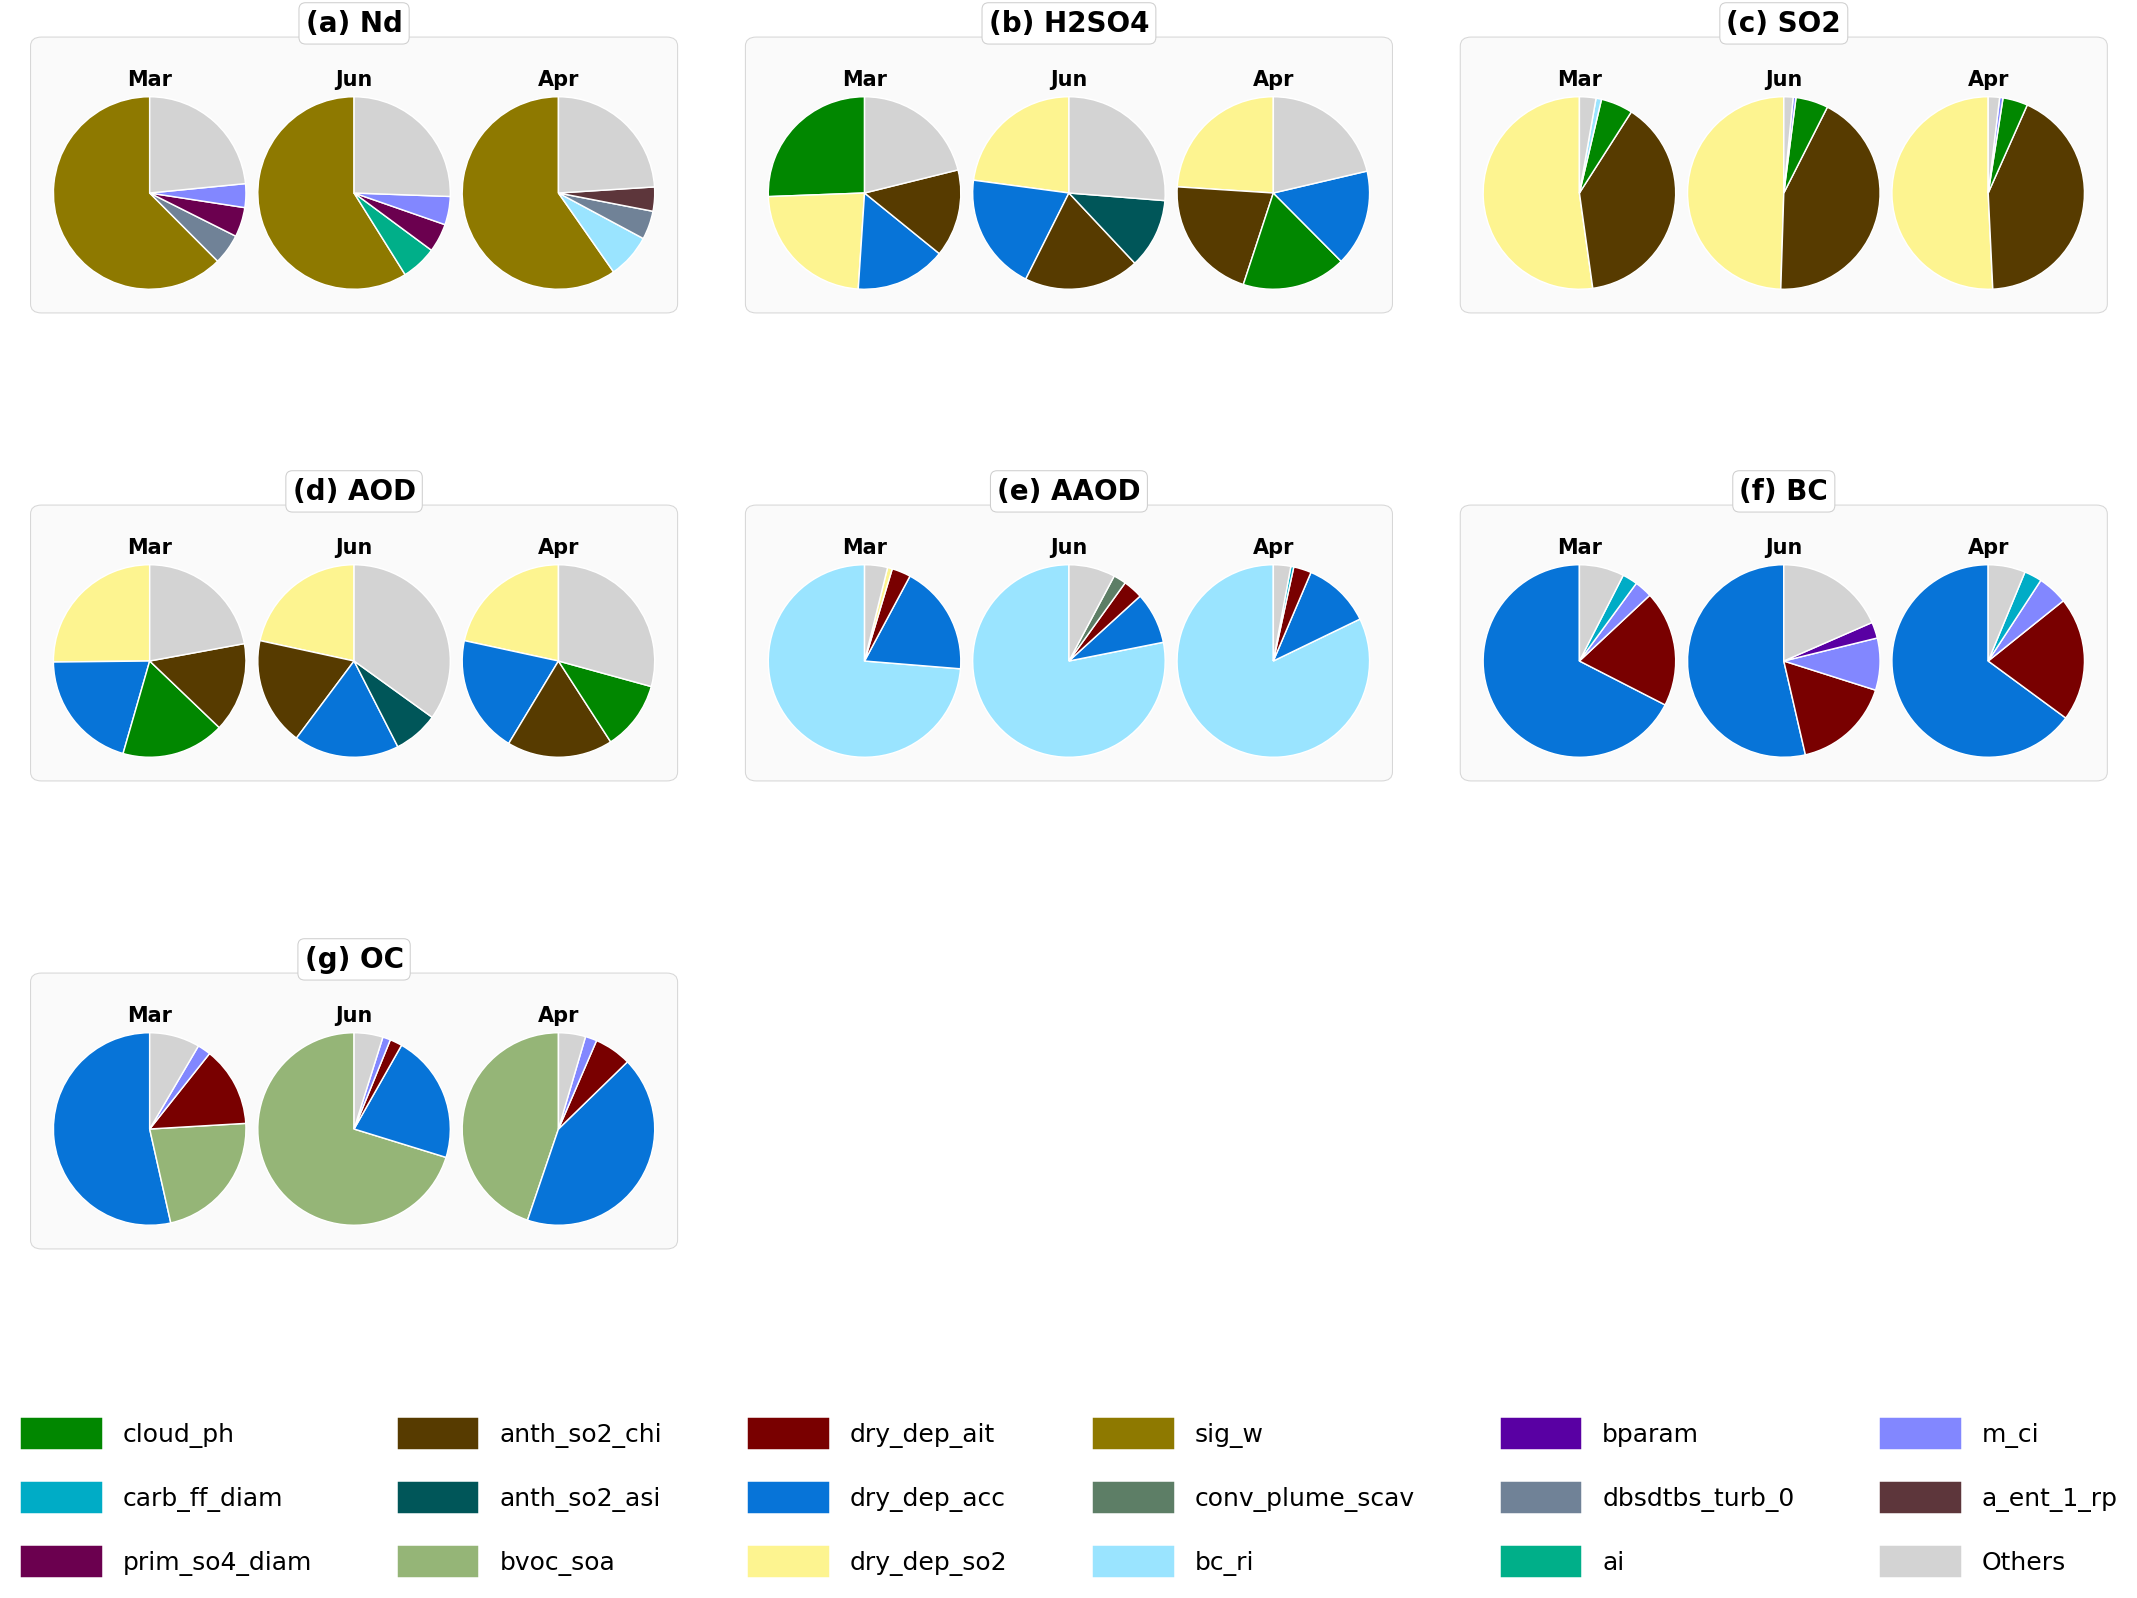

Drawing Cluster 2...


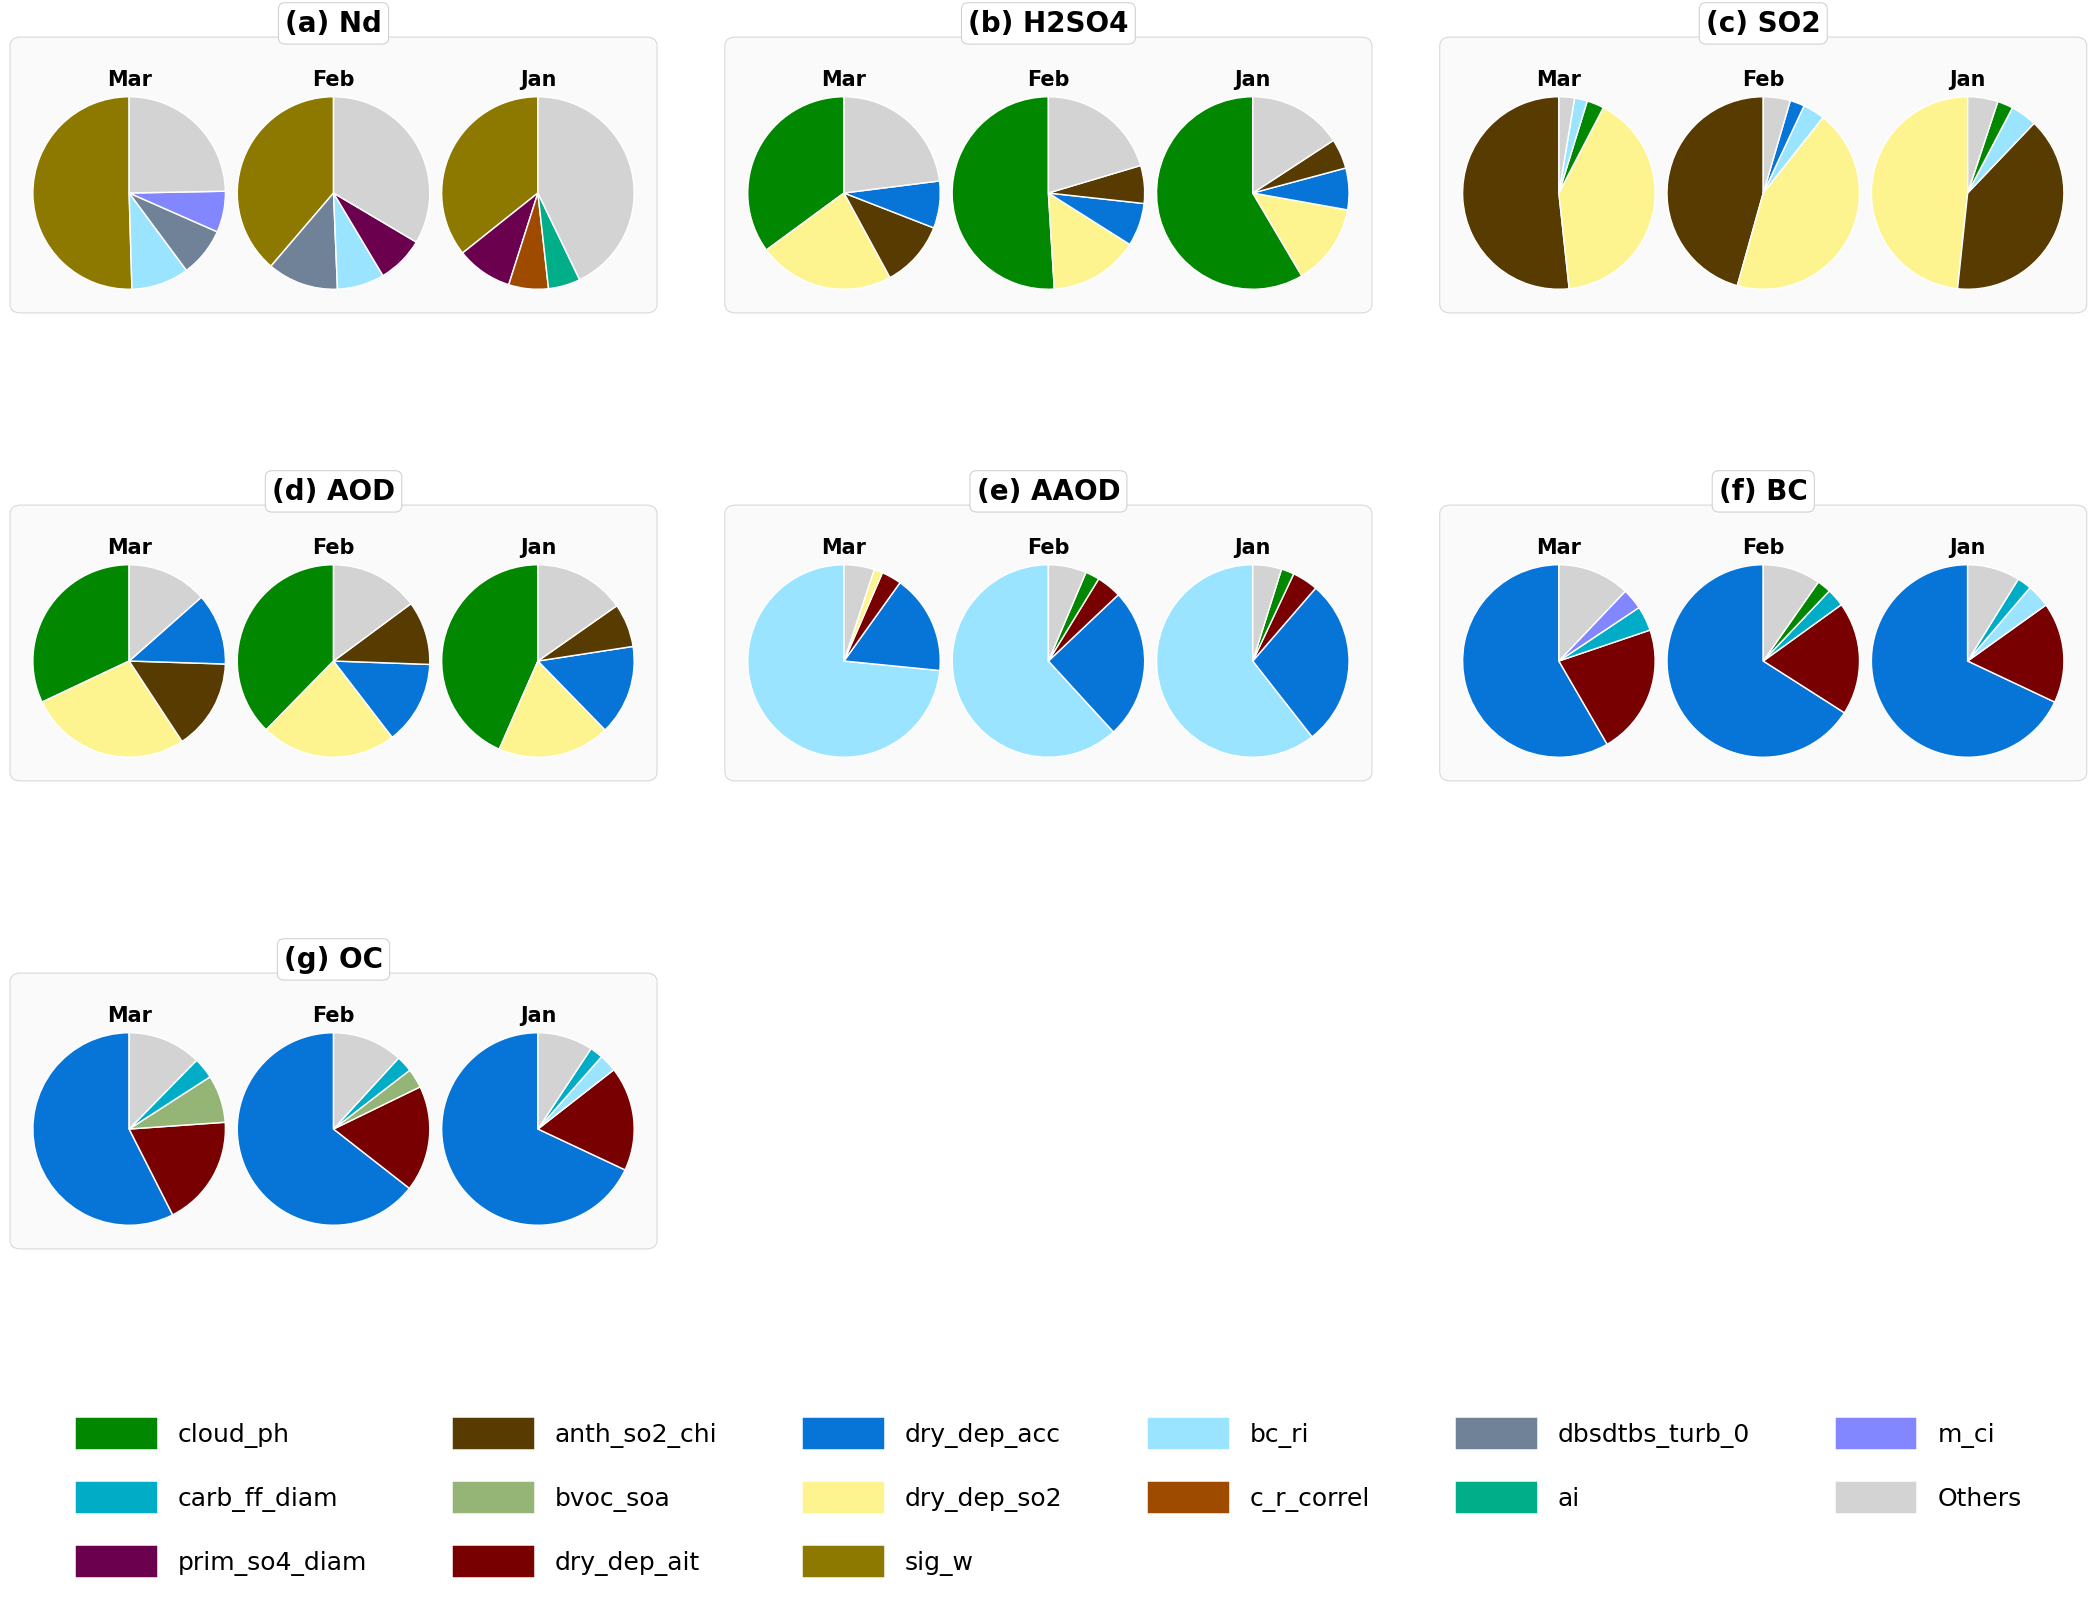

Drawing Cluster 3...


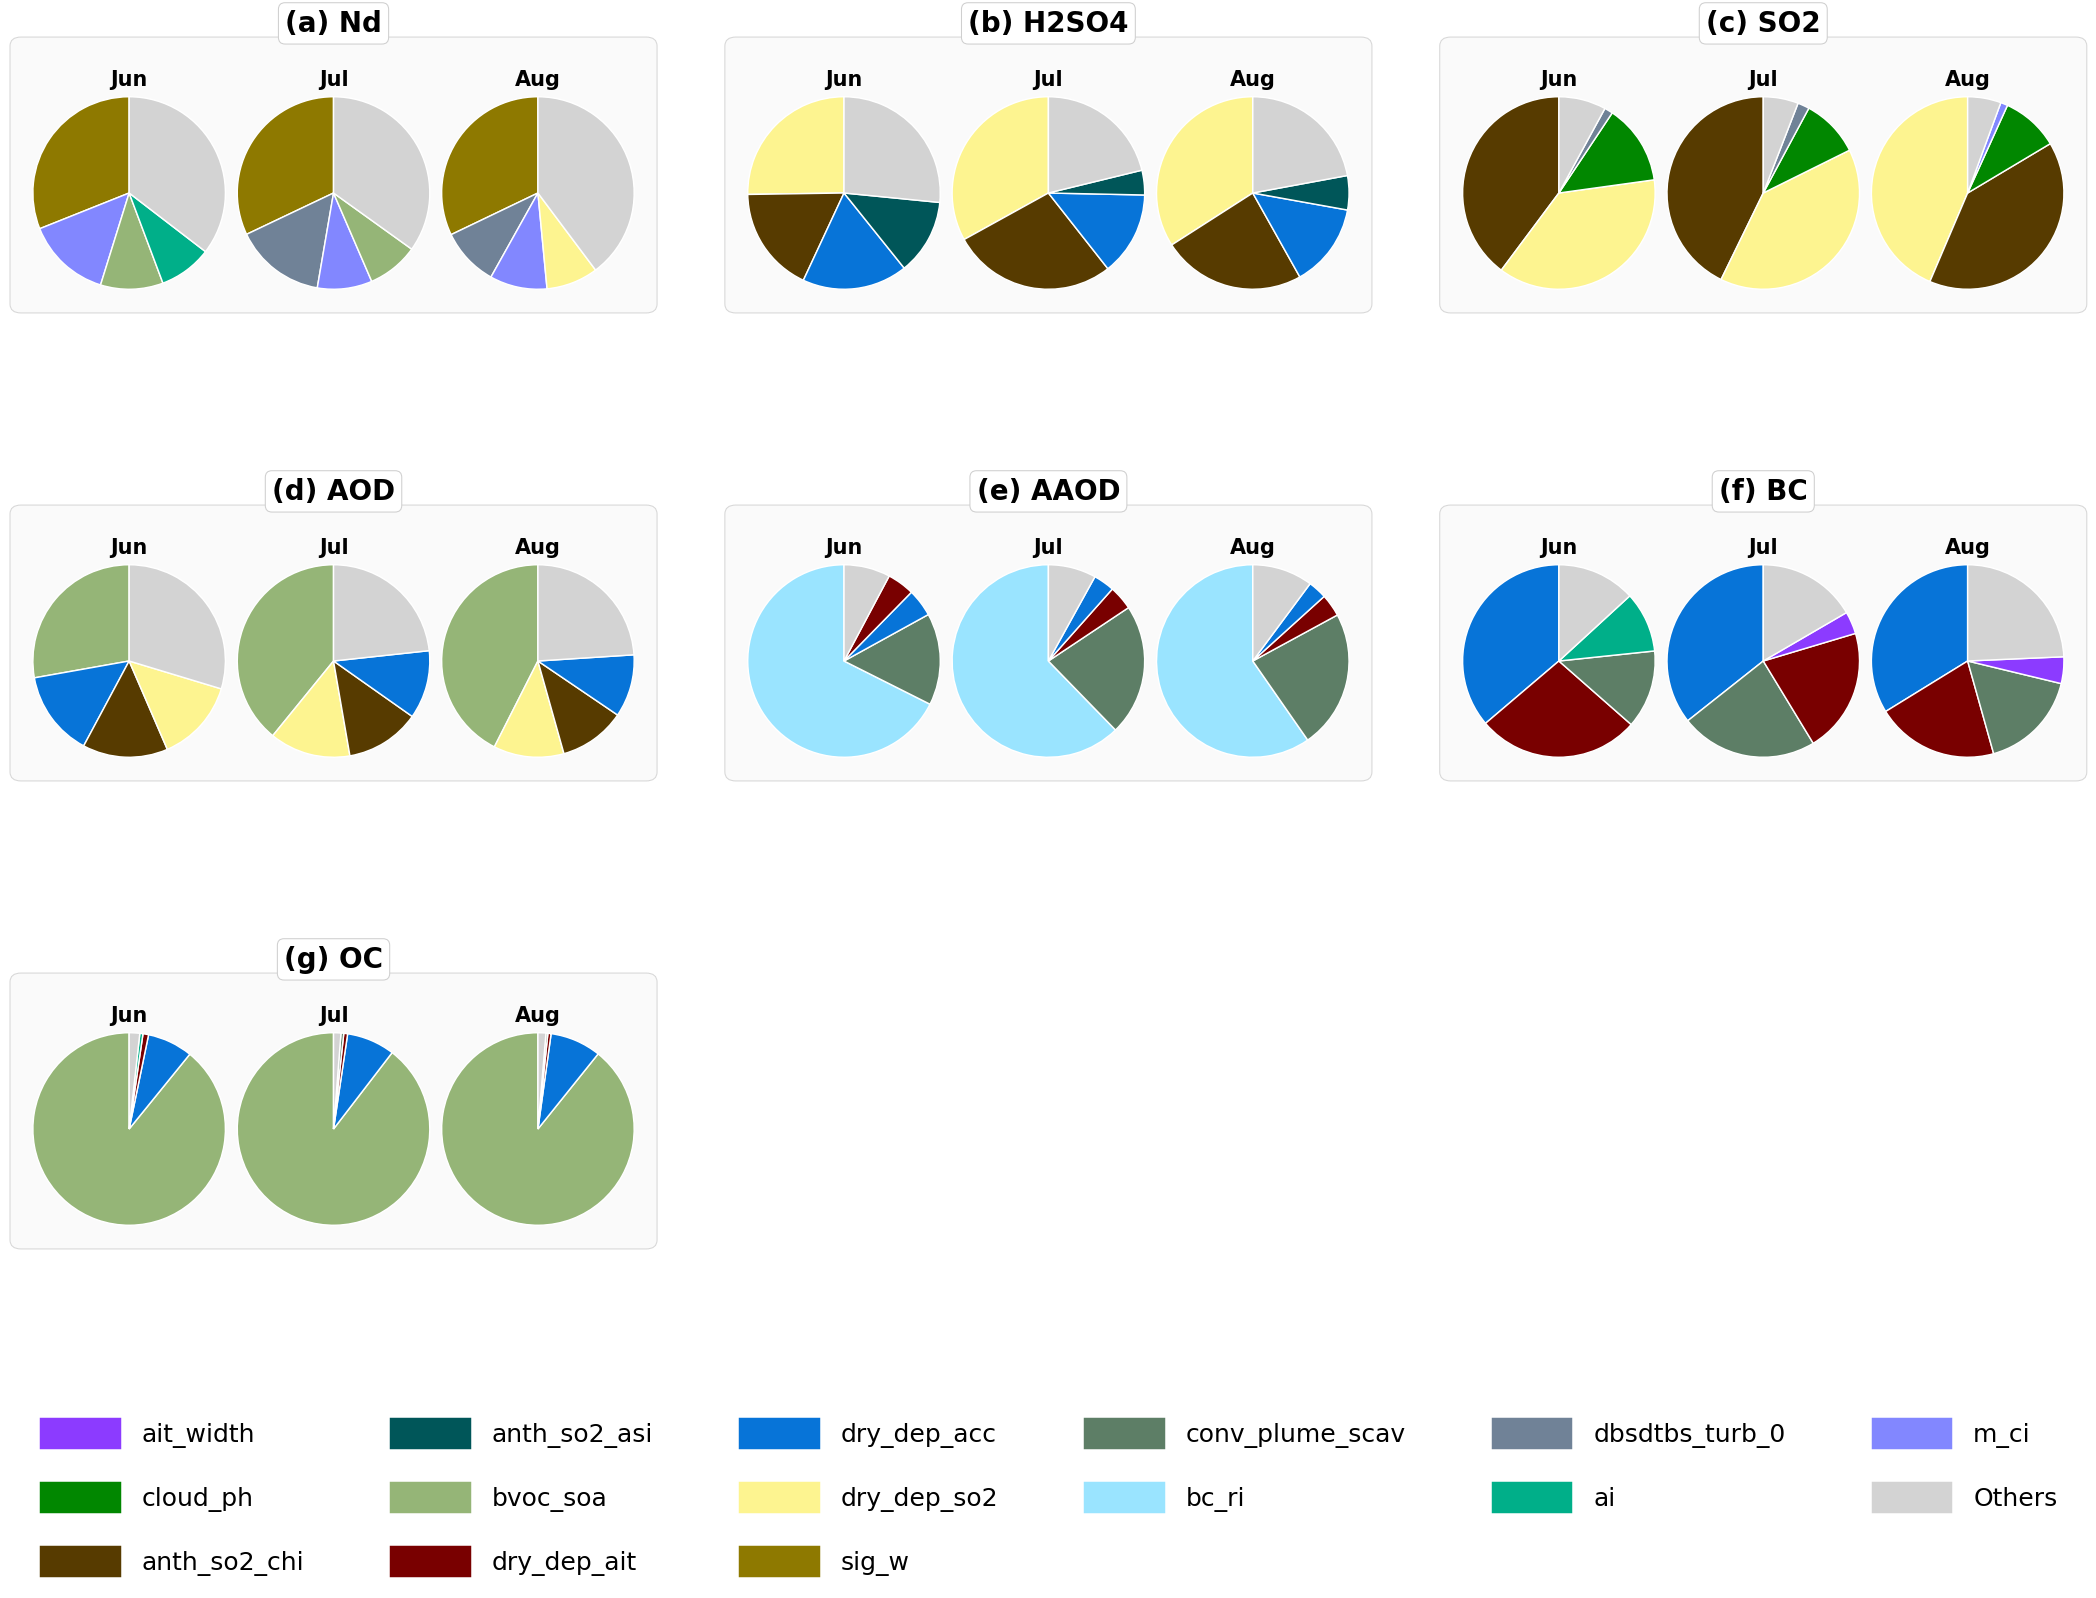

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import colorcet as cc

from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import FancyBboxPatch
from matplotlib.transforms import Bbox

# ==========================================
# CONFIGURATION
# ==========================================
variables = [
    "Nd",
    "H2SO4",
    "SO2",
    "AOD",
    "AAOD",
    "BC",
    "OC"
]

case_name = "optimal_constrained"

target_clusters = [
    "c1",
    "c5",
    "c7"
]

# 每个 cluster 对应的三个月
cluster_months = {
    "c1": ["mar", "jun", "apr"],
    "c5": ["mar", "feb", "jan"],
    "c7": ["jun", "jul", "aug"]
}

# 每个饼图只显示贡献最大的 4 个参数
top_n = 4

# cluster 名称映射
# 当前不在图中显示，仅用于程序内部识别
cluster_name_map = {
    "c1": "Cluster 1",
    "c5": "Cluster 2",
    "c7": "Cluster 3"
}

# 每个变量对应的子图标记
variable_panel_label_map = {
    "Nd": "(a)",
    "H2SO4": "(b)",
    "SO2": "(c)",
    "AOD": "(d)",
    "AAOD": "(e)",
    "BC": "(f)",
    "OC": "(g)"
}

# 月份显示名称
month_name_map = {
    "jan": "Jan",
    "feb": "Feb",
    "mar": "Mar",
    "apr": "Apr",
    "may": "May",
    "jun": "Jun",
    "jul": "Jul",
    "aug": "Aug",
    "sep": "Sep",
    "oct": "Oct",
    "nov": "Nov",
    "dec": "Dec",
    "ann": "Ann"
}

# ==========================================
# PARAMETER COLORS
# ==========================================
parameter_names_subset = [
    "bl_nuc",
    "ait_width",
    "cloud_ph",
    "carb_ff_diam",
    "carb_bb_diam",
    "carb_res_diam",
    "prim_so4_diam",
    "sea_spray",
    "anth_so2_chi",
    "anth_so2_asi",
    "anth_so2_eur",
    "anth_so2_nam",
    "anth_so2_r",
    "volc_so2",
    "bvoc_soa",
    "dms",
    "prim_moc",
    "dry_dep_ait",
    "dry_dep_acc",
    "dry_dep_so2",
    "kappa_oc",
    "sig_w",
    "rain_frac",
    "cloud_ice_thresh",
    "conv_plume_scav",
    "bc_ri",
    "oxidants_oh",
    "oxidants_o3",
    "bparam",
    "two_d_fsd_factor",
    "c_r_correl",
    "autoconv_exp_lwp",
    "autoconv_exp_nd",
    "dbsdtbs_turb_0",
    "ai",
    "m_ci",
    "a_ent_1_rp"
]

# 参数颜色严格沿用原程序
color_list = cc.glasbey[:len(parameter_names_subset)]

param_color_dict = dict(
    zip(
        parameter_names_subset,
        color_list
    )
)

PRINT_MISSING_WARNINGS = False

# Others 颜色
others_color = "#d3d3d3"

# ==========================================
# FONT AND STYLE SETTINGS
# ==========================================
variable_title_fontsize = 20
month_title_fontsize = 15
nodata_fontsize = 11

# 每张图独立 legend
legend_fontsize = 18
legend_ncol_max = 6

# 每个变量组三个月饼图的背景框
group_background_color = "#fafafa"
group_edge_color = "#d7d7d7"

# 饼图扇区之间的白色分隔线
wedge_edge_color = "white"
wedge_linewidth = 1.05

# ==========================================
# FIGURE SETTINGS
# ==========================================
figure_size = (22, 18)

# 图的边界设置
figure_left = 0.035
figure_right = 0.965
figure_top = 0.965
figure_bottom = 0.245

# 变量组之间的距离
variable_group_wspace = 0.16
variable_group_hspace = 0.30

# 三个月饼图之间的距离
month_pie_wspace = -0.015

# 饼图大小
pie_radius = 1.16

# ==========================================
# READ DATA
# ==========================================
all_data = {}

for var in variables:

    infile = (
        f"/gws/ssde/j25a/acure/jianxing/Variable/GAM_values/"
        f"{var}/summary/"
        f"{var}_GAM_cluster_month_mean_signed_response_"
        f"{case_name}.csv"
    )

    if not os.path.exists(infile):

        print(
            f"[WARN] Input file not found: {infile}"
        )

        all_data[var] = None
        continue

    df = pd.read_csv(infile)

    required_cols = [
        "var",
        "case",
        "month",
        "cluster",
        "param",
        "signed_response"
    ]

    missing_cols = [
        col
        for col in required_cols
        if col not in df.columns
    ]

    if missing_cols:

        raise ValueError(
            f"Missing required columns in input file "
            f"{infile}: {missing_cols}"
        )

    all_data[var] = df


# ==========================================
# FUNCTION: DRAW ONE CLUSTER FIGURE
# ==========================================
def plot_one_cluster(cluster):

    # ==========================================
    # CREATE ONE FIGURE FOR ONE CLUSTER
    # ==========================================
    fig = plt.figure(
        figsize=figure_size,
        facecolor="white"
    )

    # 每张图使用 3 × 3 布局：
    #
    # Row 1: Nd, H2SO4, SO2
    # Row 2: AOD, AAOD, BC
    # Row 3: OC, empty, empty
    #
    # 底部为 legend 预留空间
    main_gs = GridSpec(
        3,
        3,
        figure=fig,
        left=figure_left,
        right=figure_right,
        top=figure_top,
        bottom=figure_bottom,
        wspace=variable_group_wspace,
        hspace=variable_group_hspace
    )

    # 记录当前 cluster 图中进入 Top 4 的参数
    used_parameters = set()

    # 当前 cluster 中只要存在非 Top4参数，就显示 Others
    used_others = False

    # 保存当前 cluster 所有变量组三个月饼图的坐标轴
    variable_axes_groups = []

    months_to_plot = cluster_months[cluster]

    # ==========================================
    # PROCESS EACH VARIABLE
    # ==========================================
    for ivar, var in enumerate(variables):

        variable_row = ivar // 3
        variable_col = ivar % 3

        # 每个变量包含三个小饼图
        inner_gs = GridSpecFromSubplotSpec(
            1,
            3,
            subplot_spec=main_gs[
                variable_row,
                variable_col
            ],
            wspace=month_pie_wspace
        )

        inner_axes = []

        df_var = all_data.get(
            var,
            None
        )

        # ==========================================
        # PROCESS EACH MONTH
        # ==========================================
        for imonth, month in enumerate(months_to_plot):

            ax = fig.add_subplot(
                inner_gs[
                    0,
                    imonth
                ]
            )

            inner_axes.append(ax)

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)

            # ==========================================
            # HANDLE MISSING VARIABLE DATA
            # ==========================================
            if df_var is None:

                ax.text(
                    0.5,
                    0.5,
                    "No data",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=nodata_fontsize,
                    color="#888888"
                )

                ax.set_title(
                    month_name_map.get(
                        month,
                        month
                    ),
                    fontsize=month_title_fontsize,
                    fontweight="semibold",
                    pad=3
                )

                ax.axis("off")
                continue

            # ==========================================
            # SELECT CURRENT CLUSTER AND MONTH
            # ==========================================
            sub = df_var[
                (df_var["cluster"] == cluster)
                &
                (df_var["month"] == month)
            ].copy()

            if sub.empty:

                ax.text(
                    0.5,
                    0.5,
                    "No data",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=nodata_fontsize,
                    color="#888888"
                )

                ax.set_title(
                    month_name_map.get(
                        month,
                        month
                    ),
                    fontsize=month_title_fontsize,
                    fontweight="semibold",
                    pad=3
                )

                ax.axis("off")
                continue

            # ==========================================
            # CALCULATE RESPONSE MAGNITUDE
            # ==========================================
            # Cluster 内格点已经基于 signed_response 完成平均。
            # 绘图时使用平均 signed_response 的绝对值表示响应大小。
            sub["response_magnitude"] = (
                sub["signed_response"].abs()
            )

            total_magnitude = (
                sub["response_magnitude"].sum()
            )

            if total_magnitude == 0:

                print(
                    f"[WARN] Zero total response magnitude: "
                    f"{var}, {cluster}, {month}"
                )

                ax.text(
                    0.5,
                    0.5,
                    "No response",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=nodata_fontsize,
                    color="#888888"
                )

                ax.set_title(
                    month_name_map.get(
                        month,
                        month
                    ),
                    fontsize=month_title_fontsize,
                    fontweight="semibold",
                    pad=3
                )

                ax.axis("off")
                continue

            # 当前饼图内部归一化为百分比
            sub["cluster_pct"] = (
                100.0
                * sub["response_magnitude"]
                / total_magnitude
            )

            # ==========================================
            # SORT FROM LARGE TO SMALL
            # ==========================================
            sub = sub.sort_values(
                "cluster_pct",
                ascending=False
            ).reset_index(
                drop=True
            )

            # ==========================================
            # KEEP TOP 4 PARAMETERS
            # ==========================================
            top = sub.head(
                top_n
            ).copy()

            # 其余所有参数合并为 Others
            others = sub.iloc[
                top_n:
            ].copy()

            others_sum = (
                others["cluster_pct"].sum()
            )

            if others_sum > 0:

                top = pd.concat(
                    [
                        top,
                        pd.DataFrame(
                            [
                                {
                                    "cluster": cluster,
                                    "param": "Others",
                                    "cluster_pct": others_sum
                                }
                            ]
                        )
                    ],
                    ignore_index=True
                )

                used_others = True

            # 顺序为：
            # 第1大参数、第2大参数、第3大参数、
            # 第4大参数、Others
            labels = top["param"].tolist()
            sizes = top["cluster_pct"].tolist()

            # ==========================================
            # ASSIGN FIXED PARAMETER COLORS
            # ==========================================
            colors = []

            for param in labels:

                if param == "Others":

                    colors.append(
                        others_color
                    )

                elif param in param_color_dict:

                    colors.append(
                        param_color_dict[param]
                    )

                    used_parameters.add(
                        param
                    )

                else:

                    colors.append(
                        "#808080"
                    )

                    if PRINT_MISSING_WARNINGS:

                        print(
                            f"Warning: parameter '{param}' "
                            f"is missing from "
                            f"param_color_dict."
                        )

            # ==========================================
            # DRAW PIE CHART
            # ==========================================
            ax.pie(
                sizes,
                colors=colors,
                startangle=90,
                counterclock=True,
                radius=pie_radius,
                wedgeprops={
                    "linewidth": wedge_linewidth,
                    "edgecolor": wedge_edge_color
                }
            )

            ax.set_title(
                month_name_map.get(
                    month,
                    month
                ),
                fontsize=month_title_fontsize,
                fontweight="semibold",
                pad=3
            )

            ax.set_aspect(
                "equal"
            )

        # 保存当前变量的三个坐标轴
        variable_axes_groups.append(
            inner_axes
        )

        # ==========================================
        # VARIABLE TITLE WITH PANEL LABEL
        # ==========================================
        if len(inner_axes) >= 2:

            title_ax = inner_axes[1]

        else:

            title_ax = inner_axes[0]

        variable_title = (
            f"{variable_panel_label_map[var]} {var}"
        )

        title_ax.text(
            0.5,
            1.25,
            variable_title,
            transform=title_ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=variable_title_fontsize,
            fontweight="bold",
            bbox={
                "boxstyle": "round,pad=0.24",
                "facecolor": "white",
                "edgecolor": "#cfcfcf",
                "linewidth": 0.75
            }
        )

    # ==========================================
    # EMPTY PANELS
    # ==========================================
    # variables共有7个，因此最后两个格子为空。
    for empty_position in [
        (2, 1),
        (2, 2)
    ]:

        empty_ax = fig.add_subplot(
            main_gs[
                empty_position[0],
                empty_position[1]
            ]
        )

        empty_ax.set_axis_off()

    # ==========================================
    # ADD VARIABLE GROUP BACKGROUNDS
    # ==========================================
    # 每个变量的三个月饼图周围添加浅灰色圆角框。
    fig.canvas.draw()

    for inner_axes in variable_axes_groups:

        if not inner_axes:
            continue

        group_bbox = Bbox.union(
            [
                ax.get_position()
                for ax in inner_axes
            ]
        )

        horizontal_padding = 0.004
        bottom_padding = 0.006
        top_padding = 0.026

        group_box = FancyBboxPatch(
            (
                group_bbox.x0
                - horizontal_padding,
                group_bbox.y0
                - bottom_padding
            ),
            group_bbox.width
            + 2 * horizontal_padding,
            group_bbox.height
            + bottom_padding
            + top_padding,
            boxstyle=(
                "round,pad=0.003,"
                "rounding_size=0.005"
            ),
            transform=fig.transFigure,
            facecolor=group_background_color,
            edgecolor=group_edge_color,
            linewidth=0.75,
            zorder=-5,
            clip_on=False
        )

        fig.add_artist(
            group_box
        )

    # ==========================================
    # CREATE ONE SHARED LEGEND FOR THIS CLUSTER
    # ==========================================
    # 只显示当前 cluster 中实际进入过 Top4 的参数。
    # 参数顺序按照固定的 parameter_names_subset。
    legend_parameters = [
        param
        for param in parameter_names_subset
        if param in used_parameters
    ]

    legend_handles = [
        mpatches.Patch(
            facecolor=param_color_dict[param],
            edgecolor="white",
            linewidth=1.1,
            label=param
        )
        for param in legend_parameters
    ]

    if used_others:

        legend_handles.append(
            mpatches.Patch(
                facecolor=others_color,
                edgecolor="white",
                linewidth=1.1,
                label="Others"
            )
        )

    if legend_handles:

        legend_ncol = min(
            legend_ncol_max,
            len(legend_handles)
        )

        fig.legend(
            handles=legend_handles,
            loc="lower center",
            bbox_to_anchor=(
                0.5,
                0.09
            ),
            ncol=legend_ncol,
            frameon=False,
            fontsize=legend_fontsize,
            handlelength=3.3,
            handleheight=1.65,
            handletextpad=0.8,
            columnspacing=3.4,
            labelspacing=1.25,
            borderaxespad=0.0
        )

    # ==========================================
    # SHOW CURRENT CLUSTER FIGURE
    # ==========================================
    plt.show()


# ==========================================
# DRAW THREE SEPARATE FIGURES
# ==========================================
for cluster in target_clusters:

    print(
        f"Drawing {cluster_name_map[cluster]}..."
    )

    plot_one_cluster(
        cluster
    )